# 01 — DESI DR2 Data Check

## Objective

Validate the DESI DR2 BAO mean vector and covariance matrix before running symbolic regression. This notebook reproduces the six $D_H/r_d$ measurements listed in Table I of the target paper.

### Validation requirements

- The full mean vector must contain 13 observables.
- The full covariance matrix must have shape $13 \times 13$.
- The covariance matrix must be finite, symmetric, and positive definite.
- The DESI-only sample must contain exactly six `DH_over_rs` measurements.
- Their redshifts and central values must agree with Table I.
- Covariance-derived uncertainties must be compared with, but not overwritten by, the rounded Table I uncertainties.

> Raw data are read only. This notebook does not modify the source files.

## 1. Imports and plotting style

Required packages: `numpy`, `pandas`, and `matplotlib`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", lambda value: f"{value:.6f}")

## 2. Locate and load the DESI files

The project-root search makes the notebook work whether Jupyter starts in the project directory or in `notebooks/`.

In [2]:
def find_project_root(start: Path) -> Path:
    """Return the nearest parent containing the DESI data directory."""
    for candidate in (start, *start.parents):
        if (candidate / "Data" / "DESI_BAO").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate Data/DESI_BAO from the current directory.")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
DATA_DIR = PROJECT_ROOT / "Data" / "DESI_BAO"
MEAN_FILE = DATA_DIR / "desi_gaussian_bao_ALL_GCcomb_mean.txt"
COV_FILE = DATA_DIR / "desi_gaussian_bao_ALL_GCcomb_cov.txt"

if not MEAN_FILE.is_file() or not COV_FILE.is_file():
    raise FileNotFoundError("One or more DESI input files are missing.")

# Parse the three-column mean vector and the full covariance matrix.
desi_all = pd.read_csv(
    MEAN_FILE,
    sep=r"\s+",
    comment="#",
    names=["z", "value", "quantity"],
)
cov_all = np.loadtxt(COV_FILE)

print(f"Project root: {PROJECT_ROOT}")
print(f"Mean-vector entries: {len(desi_all)}")
print(f"Covariance shape: {cov_all.shape}")
display(desi_all)

Project root: /Users/kemingliu/Desktop/Dark Energy
Mean-vector entries: 13
Covariance shape: (13, 13)


,z,value,quantity
0,0.295000,7.941676,DV_over_rs
1,0.510000,13.587584,DM_over_rs
2,0.510000,21.862947,DH_over_rs
3,0.706000,17.350691,DM_over_rs
4,0.706000,19.455349,DH_over_rs
5,0.934000,21.575640,DM_over_rs
6,0.934000,17.641495,DH_over_rs
7,1.321000,27.600856,DM_over_rs
8,1.321000,14.176022,DH_over_rs
9,1.484000,30.511901,DM_over_rs


## 3. Validate the full covariance matrix

A failed assertion means the input files or their ordering must be investigated before continuing. Positive definiteness is checked through the covariance eigenvalues.

In [3]:
N_EXPECTED = 13

assert len(desi_all) == N_EXPECTED, "Expected 13 DESI observables."
assert cov_all.shape == (N_EXPECTED, N_EXPECTED), "Expected a 13 x 13 covariance matrix."
assert np.isfinite(desi_all[["z", "value"]].to_numpy()).all(), "The mean vector contains non-finite values."
assert np.isfinite(cov_all).all(), "The covariance matrix contains non-finite values."
assert np.allclose(cov_all, cov_all.T, rtol=0.0, atol=1e-12), "The covariance matrix is not symmetric."
assert np.all(np.diag(cov_all) > 0.0), "All covariance diagonal entries must be positive."

eigenvalues = np.linalg.eigvalsh(cov_all)
assert eigenvalues.min() > 0.0, "The covariance matrix is not positive definite."

print("Full DESI input validation: PASSED")
print(f"Smallest covariance eigenvalue: {eigenvalues.min():.6e}")
print("Observable counts:")
display(desi_all["quantity"].value_counts().rename("count").to_frame())

Full DESI input validation: PASSED
Smallest covariance eigenvalue: 5.789987e-03
Observable counts:


,count
quantity,
DM_over_rs,6
DH_over_rs,6
DV_over_rs,1


## 4. Select the six radial BAO measurements

For the DESI-only reconstruction, the paper uses only $D_H/r_d$. The single $D_V/r_d$ measurement and all $D_M/r_d$ measurements are excluded. The same Boolean mask must be applied to both axes of the covariance matrix.

In [4]:
dh_mask = desi_all["quantity"].eq("DH_over_rs").to_numpy()
dh_indices = np.flatnonzero(dh_mask)

desi_dh = desi_all.loc[dh_mask, ["z", "value"]].reset_index(drop=True)
# Apply the selected mean-vector indices to both covariance axes.
cov_dh = cov_all[np.ix_(dh_indices, dh_indices)]
desi_dh["sigma"] = np.sqrt(np.diag(cov_dh))

assert len(desi_dh) == 6, "Expected exactly six DH/rd measurements."
assert cov_dh.shape == (6, 6), "Expected a 6 x 6 DH/rd covariance matrix."
assert np.linalg.eigvalsh(cov_dh).min() > 0.0, "The selected covariance is not positive definite."

print(f"Selected mean-vector indices: {dh_indices.tolist()}")
print(f"Selected measurements: {len(desi_dh)}")
display(desi_dh)

Selected mean-vector indices: [2, 4, 6, 8, 10, 11]
Selected measurements: 6


,z,value,sigma
0,0.510000,21.862947,0.428868
1,0.706000,19.455349,0.333870
2,0.934000,17.641495,0.201043
3,1.321000,14.176022,0.224551
4,1.484000,12.817000,0.518012
5,2.330000,8.631546,0.101062


## 5. Compare with Table I of the paper

Central values are checked against the higher-precision data-release values. The published uncertainties are compared with $\sqrt{\mathrm{diag}(C)}$ and any discrepancy is reported explicitly. The covariance-derived values remain authoritative for the covariance-weighted loss in notebook 02.

In [5]:
tracers = np.array(["LRG1", "LRG2", "LRG3+ELG1", "ELG2", "QSO", "Ly-alpha"])
paper_z = np.array([0.510, 0.706, 0.934, 1.321, 1.484, 2.330])
paper_dh = np.array([21.863, 19.455, 17.641, 14.176, 12.817, 8.632])
paper_sigma = np.array([0.425, 0.330, 0.193, 0.221, 0.516, 0.101])

# The paper values are rounded, so the absolute tolerance is half of the final quoted decimal unit.
np.testing.assert_allclose(desi_dh["z"], paper_z, rtol=0.0, atol=5e-7)
np.testing.assert_allclose(desi_dh["value"], paper_dh, rtol=0.0, atol=5e-4)

comparison = pd.DataFrame(
    {
        "tracer": tracers,
        "z_eff": desi_dh["z"],
        "data_DH_over_rd": desi_dh["value"],
        "paper_DH_over_rd": paper_dh,
        "data_sigma": desi_dh["sigma"],
        "paper_sigma": paper_sigma,
    }
)
comparison["delta_DH"] = comparison["data_DH_over_rd"] - comparison["paper_DH_over_rd"]
comparison["delta_sigma"] = comparison["data_sigma"] - comparison["paper_sigma"]
comparison["relative_delta_sigma_percent"] = 100.0 * comparison["delta_sigma"] / comparison["paper_sigma"]

max_sigma_difference = comparison["relative_delta_sigma_percent"].abs().max()
assert max_sigma_difference < 5.0, "Covariance-derived uncertainties differ from Table I by at least 5%."

print("Table I redshift and central-value comparison: PASSED")
print(f"Maximum relative uncertainty difference: {max_sigma_difference:.2f}%")
print("Note: notebook 02 must use cov_dh, not the rounded paper uncertainties.")
display(comparison)

Table I redshift and central-value comparison: PASSED
Maximum relative uncertainty difference: 4.17%
Note: notebook 02 must use cov_dh, not the rounded paper uncertainties.


,tracer,z_eff,data_DH_over_rd,paper_DH_over_rd,data_sigma,paper_sigma,delta_DH,delta_sigma,relative_delta_sigma_percent
0,LRG1,0.510000,21.862947,21.863000,0.428868,0.425000,-0.000053,0.003868,0.910194
1,LRG2,0.706000,19.455349,19.455000,0.333870,0.330000,0.000349,0.003870,1.172737
2,LRG3+ELG1,0.934000,17.641495,17.641000,0.201043,0.193000,0.000495,0.008043,4.167486
3,ELG2,1.321000,14.176022,14.176000,0.224551,0.221000,0.000022,0.003551,1.606946
4,QSO,1.484000,12.817000,12.817000,0.518012,0.516000,-0.000000,0.002012,0.389878
5,Ly-alpha,2.330000,8.631546,8.632000,0.101062,0.101000,-0.000454,0.000062,0.061835


## 6. Inspect the selected measurements and correlations

The left panel shows the six DESI-only measurements. The right panel checks whether the selected $D_H/r_d$ measurements retain non-zero correlations.

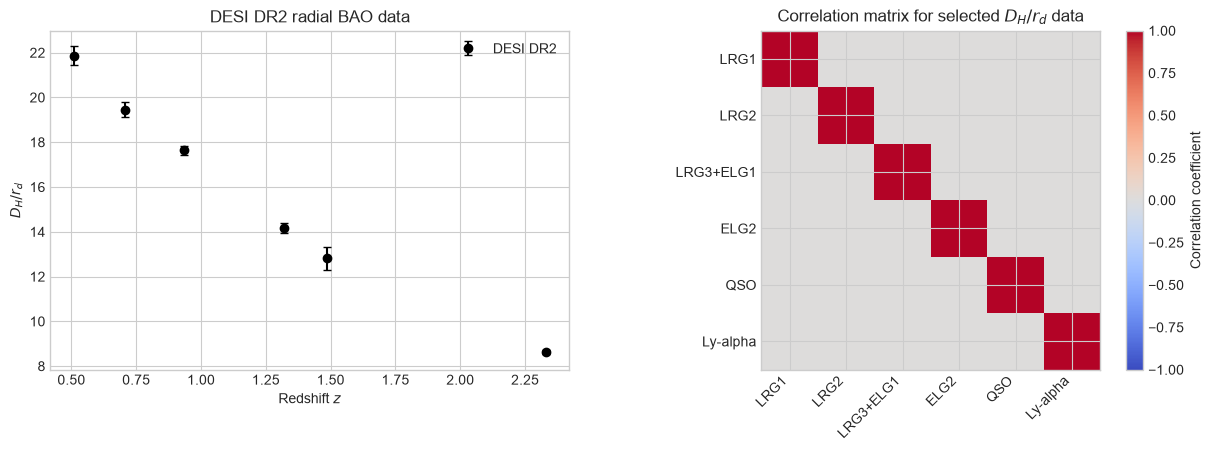

In [6]:
# Normalize the covariance matrix to obtain dimensionless correlation coefficients.
sigma_outer = np.outer(desi_dh["sigma"], desi_dh["sigma"])
corr_dh = cov_dh / sigma_outer

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)

axes[0].errorbar(
    desi_dh["z"],
    desi_dh["value"],
    yerr=desi_dh["sigma"],
    fmt="o",
    color="black",
    capsize=3,
    label="DESI DR2",
)
axes[0].set(xlabel=r"Redshift $z$", ylabel=r"$D_H/r_d$", title=r"DESI DR2 radial BAO data")
axes[0].legend(frameon=False)

image = axes[1].imshow(corr_dh, vmin=-1.0, vmax=1.0, cmap="coolwarm")
axes[1].set_xticks(range(len(tracers)), tracers, rotation=45, ha="right")
axes[1].set_yticks(range(len(tracers)), tracers)
axes[1].set_title(r"Correlation matrix for selected $D_H/r_d$ data")
fig.colorbar(image, ax=axes[1], label="Correlation coefficient")

plt.show()

## 7. Export the validated DESI-only dataset

The processed file contains the six measurements and their full covariance matrix. Notebook 02 can load this file without repeating the selection logic.

In [7]:
OUTPUT_DIR = PROJECT_ROOT / "results" / "01_desi_data_check"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_FILE = OUTPUT_DIR / "desi_dr2_dh_over_rd.npz"

# Save derived arrays separately and leave the raw DESI files unchanged.
np.savez(
    OUTPUT_FILE,
    z=desi_dh["z"].to_numpy(),
    y=desi_dh["value"].to_numpy(),
    covariance=cov_dh,
    sigma=desi_dh["sigma"].to_numpy(),
    tracers=tracers,
)

print(f"Saved validated dataset to: {OUTPUT_FILE}")

Saved validated dataset to: /Users/kemingliu/Desktop/Dark Energy/results/01_desi_data_check/desi_dr2_dh_over_rd.npz


## Conclusion

The notebook is complete when every assertion passes and the final sample contains six $D_H/r_d$ measurements. The DESI redshifts and central values agree with Table I. Small differences between the covariance-derived uncertainties and the rounded uncertainties quoted in the paper are retained and documented rather than manually corrected. The validated output is then ready for the covariance-weighted symbolic-regression analysis in notebook 02.